# XY model in emu-mps, driven by a pulser sequence

The XY (spin-exchange, hopping) model on any coupling graph,

$$
H(t) = \sum_j \frac{\Omega_j(t)}{2}\big[\cos\phi_j X_j + \sin\phi_j Y_j\big] - \sum_j \Delta_j(t)\, n_j
 + \sum_{i<j} \frac{J_{ij}}{2} \big( X_iX_j + Y_iY_j \big),
\qquad \frac{1}{2}(X_iX_j + Y_iY_j) = \sigma^+_i\sigma^-_j + \sigma^-_i\sigma^+_j ,
$$

with Pauli matrices $X, Y$, $n = |d\rangle\langle d| = (1-Z)/2$ (pulser's XY basis `("u", "d")`, $|u\rangle$ = index 0),
frequencies in rad/µs and times in ns.

Unlike Heisenberg, XY is pulser's own `mw_global` channel, so emu-mps runs it with the plain `MPSBackend(seq, config).run()`.
pulser / emu-base hand emu-mps a 2-layer stack `[J, C6]`: the first layer gives $\frac{J_{ij}}{2}(X_iX_j+Y_iY_j)$, the
second a $C_6^{ij}|u\rangle\langle u|_i|u\rangle\langle u|_j$ shift. Three routes to an XY Hamiltonian:

1. **pulser default**: the register's dipolar couplings $C_3(1-3\cos^2\theta_{ij})/r_{ij}^3$ plus pulser's $C_6/r^6$ shift;
2. **custom (pulser XY)**: any coupling graph with `MPSConfig(interaction_matrix=[J, 0])` (pure XY);
3. **custom (Heisenberg stack)**: the same model as the Heisenberg stack $J^{xx} = J^{yy} = J/2$, $J^{zz} = 0$
   (see `heisenberg.ipynb`; also gives XXZ models with $J^{zz} \neq 0$).

Initial states in the XY basis come from `MPS.from_state_amplitudes(eigenstates=("u", "d"), ...)`.
Every emu-mps result is checked against an exact dense simulation: state vector without noise, Lindblad master
equation with noise, for a **pulsed** and a **free** (no pulse) sequence.

In [1]:
import dataclasses
import logging
import random
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from pulser.devices import MockDevice

from emu_base import PulserData
from emu_mps import MPS, MPSBackend, MPSConfig, CorrelationMatrix, Occupation, StateResult

dtype = torch.complex128
random.seed(0)  # emu-mps quantum jumps use python's `random`
torch.manual_seed(0)

## 1. Register, couplings and sequences

A chain of 6 atoms, 18 µm apart (the geometry only matters for pulser's default couplings). The custom couplings are
an SSH-like chain with alternating strong / weak bonds, closed into a ring by a long-range bond 0-5: a graph no
geometry of a chain would give. Two sequences on the global microwave (XY) channel of `MockDevice`:
- **pulsed**: Blackman π-pulse with a linear detuning ramp from -3 to 3 rad/µs, from the Néel state $|udud\dots\rangle$;
- **free**: a delay of the same duration, i.e. $\Omega=\Delta=0$, from one excitation $|uuduuu\rangle$: pure hopping.

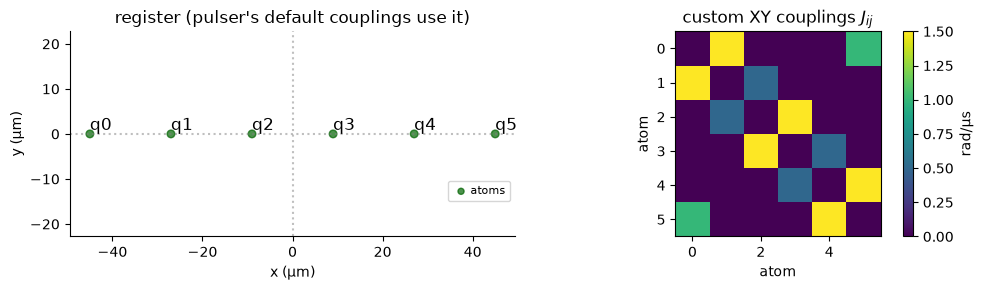

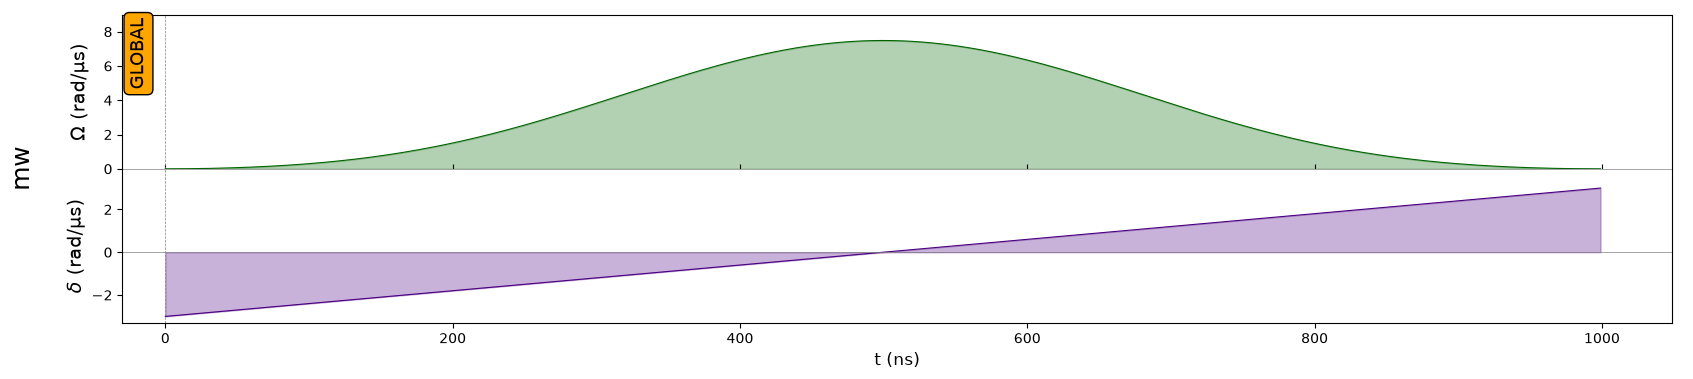

In [2]:
n, T, dt = 6, 1000, 10  # atoms, duration (ns), emu-mps time step (ns)
reg = pulser.Register.rectangle(1, n, spacing=18.0, prefix="q")

J = np.zeros((n, n))  # custom XY couplings J_ij (rad/µs)
for i in range(n - 1):
    J[i, i + 1] = 1.5 if i % 2 == 0 else 0.5  # alternating strong / weak bonds
J[0, n - 1] = 1.0  # closes the ring: a long-range bond for the MPS
J = J + J.T


def make_sequence(pulsed):
    seq = pulser.Sequence(reg, MockDevice)
    seq.declare_channel("mw", "mw_global")
    if pulsed:
        pulse = pulser.Pulse(
            amplitude=pulser.BlackmanWaveform(T, area=np.pi),
            detuning=pulser.RampWaveform(T, -3.0, 3.0),
            phase=0.0,
        )
        seq.add(pulse, "mw")
    else:
        seq.delay(T, "mw")
    return seq


cases = {  # name: (sequence, initial state in the XY basis)
    "pulsed": (make_sequence(True), "ud" * (n // 2)),
    "free": (make_sequence(False), "uuduuu"),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
reg.draw(custom_ax=axes[0], show=False)
axes[0].set_title("register (pulser's default couplings use it)")
fig.colorbar(axes[1].imshow(J, cmap="viridis"), ax=axes[1], label="rad/µs")
axes[1].set_title("custom XY couplings $J_{ij}$"); axes[1].set_xlabel("atom"); axes[1].set_ylabel("atom")
fig.tight_layout()
cases["pulsed"][0].draw()

## 2. Exact references

Dense $2^n$ simulations driven by the very same `SequenceData` arrays as emu-mps (`PulserData` samples the sequence
exactly as `MPSBackend.run` does: `omega[k]`, `delta[k]`, `phi[k]` constant on `[target_times[k], target_times[k+1]]`),
with the interaction written out from Pauli matrices: $\frac{J_{ij}}{2}(X_iX_j + Y_iY_j)$ plus, for pulser's default
couplings, the $C_6^{ij} |u\rangle\langle u|_i |u\rangle\langle u|_j$ shift. We record $\langle n_j \rangle(t)$ and
$\langle n_i n_j \rangle(t)$, what emu-mps' `Occupation` and `CorrelationMatrix` measure.

In [3]:
X = torch.tensor([[0, 1], [1, 0]], dtype=dtype)
Y = torch.tensor([[0, -1j], [1j, 0]], dtype=dtype)
Nd = torch.tensor([[0, 0], [0, 1]], dtype=dtype)  # |d><d|, index 1
Pu = torch.tensor([[1, 0], [0, 0]], dtype=dtype)  # |u><u|, index 0


def op(single, i):
    # single-qubit operator on qubit i; qubit 0 is the most significant bit
    return reduce(torch.kron, [single if k == i else torch.eye(2, dtype=dtype) for k in range(n)])


N_ops = [op(Nd, j) for j in range(n)]
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]


def index(ud):
    return int(ud.replace("u", "0").replace("d", "1"), 2)


def interaction(J_xy, C6=None):
    H = sum(J_xy[i, j] / 2 * (op(X, i) @ op(X, j) + op(Y, i) @ op(Y, j)) for i, j in pairs)
    if C6 is not None:
        H = H + sum(C6[i, j] * op(Pu, i) @ op(Pu, j) for i, j in pairs)
    return H


def hamiltonians(sd, H_int):
    # one dense H per time step
    w, d, p = sd.omega.real, sd.delta.real, sd.phi.real
    return [
        H_int + sum(
            w[k, j] / 2 * (torch.cos(p[k, j]) * op(X, j) + torch.sin(p[k, j]) * op(Y, j)) - d[k, j] * N_ops[j]
            for j in range(n)
        )
        for k in range(len(w))
    ]


def exact_state_dynamics(sd, H_int, ud):
    psi = torch.zeros(2**n, dtype=dtype)
    psi[index(ud)] = 1.0
    occ, corr = [], []

    def record():
        occ.append(torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops]))
        corr.append(torch.stack([torch.stack([torch.vdot(psi, Ni @ Nj @ psi).real for Nj in N_ops]) for Ni in N_ops]))

    record()
    for H, t0, t1 in zip(hamiltonians(sd, H_int), sd.target_times, sd.target_times[1:]):
        psi = torch.linalg.matrix_exp(-1j * H * (t1 - t0) / 1000) @ psi  # µs
        record()
    return torch.stack(occ), torch.stack(corr), psi


def exact_lindblad_dynamics(sd, H_int, ud, n_sub=10):
    # RK4 on rho' = -i[H, rho] + sum_k L rho L^+ - 1/2 {L^+ L, rho}
    Ls = [op(L, j) for L in sd.lindblad_ops for j in range(n)]
    LdL = sum(L.mH @ L for L in Ls)

    def rhs(rho, H_eff):
        out = -1j * (H_eff @ rho - rho @ H_eff.mH)
        for L in Ls:
            out += L @ rho @ L.mH
        return out

    rho = torch.zeros(2**n, 2**n, dtype=dtype)
    rho[index(ud), index(ud)] = 1.0
    occ = [torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops])]
    for H, t0, t1 in zip(hamiltonians(sd, H_int), sd.target_times, sd.target_times[1:]):
        H_eff, h = H - 0.5j * LdL, (t1 - t0) / 1000 / n_sub
        for _ in range(n_sub):
            k1 = rhs(rho, H_eff)
            k2 = rhs(rho + h / 2 * k1, H_eff)
            k3 = rhs(rho + h / 2 * k2, H_eff)
            k4 = rhs(rho + h * k3, H_eff)
            rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        occ.append(torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops]))
    return torch.stack(occ)

## 3. emu-mps vs exact: three routes to an XY Hamiltonian

- **pulser default** and **custom (pulser XY)** are ordinary pulser runs: `MPSBackend(seq, config).run()`;
- **custom (Heisenberg stack)** replaces the `SequenceData` interaction matrix by `[J/2, J/2, 0]` and runs
  `MPSBackend._run_from_sequence_data`, as in `heisenberg.ipynb`.

Qubit reordering is off so qubit indices match the exact simulation.

In [4]:
zeros = np.zeros((n, n))
routes = ["pulser default", "custom (pulser XY)", "custom (Heisenberg stack)"]


def run_mps(route, seq, ud, *observables, noise_model=None):
    extra = dict(interaction_matrix=np.stack([J, zeros])) if route == "custom (pulser XY)" else {}
    config = MPSConfig(
        dt=dt,
        observables=list(observables),
        initial_state=MPS.from_state_amplitudes(eigenstates=("u", "d"), amplitudes={ud: 1.0}),
        noise_model=noise_model,
        optimize_qubit_ordering=False,
        precision=1e-9,
        log_level=logging.WARN,
        **extra,
    )
    if route != "custom (Heisenberg stack)":
        return MPSBackend(seq, config=config).run()
    (sd,) = PulserData(sequence=seq, config=config, dt=dt).get_sequences()
    Jxy = torch.tensor(J, dtype=torch.float64)
    stack = torch.stack([Jxy / 2, Jxy / 2, torch.zeros_like(Jxy)])  # 3 x n x n => Heisenberg
    return MPSBackend._run_from_sequence_data(dataclasses.replace(sd, interaction_matrix=lambda t: stack), config)


def exact_interaction(route, sd):
    if route != "pulser default":
        return interaction(J)
    C3, C6 = sd.interaction_matrix(0.0)  # pulser's default XY stack
    return interaction(C3, C6)


exact, mps = {}, {}
for case, (seq, ud) in cases.items():
    (sd,) = PulserData(sequence=seq, config=MPSConfig(dt=dt), dt=dt).get_sequences()
    times = np.array(sd.target_times)
    eval_times = list((times - times[0]) / (times[-1] - times[0]))
    for route in routes:
        occ, corr, psi_exact = exact_state_dynamics(sd, exact_interaction(route, sd), ud)
        exact[case, route] = dict(occ=occ, corr=corr)
        res = run_mps(route, seq, ud, Occupation(evaluation_times=eval_times),
                      CorrelationMatrix(evaluation_times=eval_times), StateResult(evaluation_times=[1.0]))
        mps[case, route] = dict(occ=torch.stack([torch.as_tensor(o) for o in res.occupation]),
                                corr=torch.stack([torch.as_tensor(c).real for c in res.correlation_matrix]))
        psi_mps = reduce(lambda a, b: torch.tensordot(a, b, dims=1), res.state[-1].factors).reshape(-1).cpu()
        print(
            f"{case:>6} | {route:26s}: final fidelity {abs(torch.vdot(psi_exact, psi_mps)) ** 2:.8f}, "
            f"max error <n_i> {(mps[case, route]['occ'] - occ).abs().max():.1e}, "
            f"<n_i n_j> {(mps[case, route]['corr'] - corr).abs().max():.1e}, "
            f"max bond dim {res.state[-1].get_max_bond_dim()}"
        )

d = max(float((mps[c, routes[1]]["occ"] - mps[c, routes[2]]["occ"]).abs().max()) for c in cases)
print(f"pulser XY route vs Heisenberg-stack route: max |d<n_i>| = {d:.1e}")

/Users/i.sokolov/Code/emulators/ci/emu_mps/emu_mps/mps_config.py:111: UserWarning: 'MPSConfig' was initialized without any observables. The corresponding emulation results will be empty.
  super().__init__(


emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


pulsed | pulser default            : final fidelity 0.99999583, max error <n_i> 1.1e-03, <n_i n_j> 1.4e-03, max bond dim 8


emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


...

emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


  free | pulser default            : final fidelity 0.99998464, max error <n_i> 2.6e-03, <n_i n_j> 2.6e-03, max bond dim 6
emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


  free | custom (pulser XY)        : final fidelity 1.00000000, max error <n_i> 4.7e-06, <n_i n_j> 4.7e-06, max bond dim 4
emu-mps allows only {'energy_second_moment', 'statistics', 'occupation', 'bitstrings', 'correlation_matrix', 'energy_variance', 'energy'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


  free | custom (Heisenberg stack) : final fidelity 1.00000000, max error <n_i> 3.8e-06, <n_i n_j> 3.8e-06, max bond dim 4
pulser XY route vs Heisenberg-stack route: max |d<n_i>| = 1.8e-06


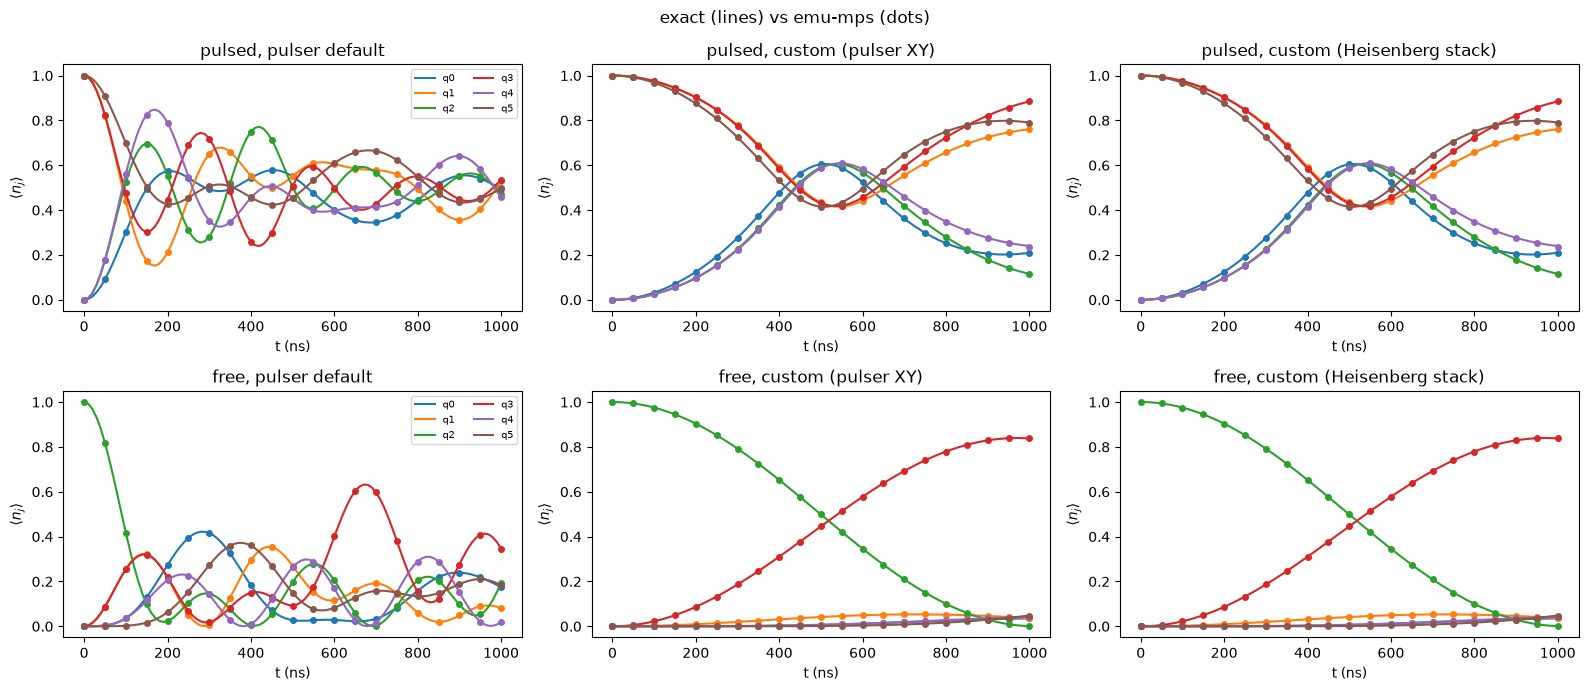

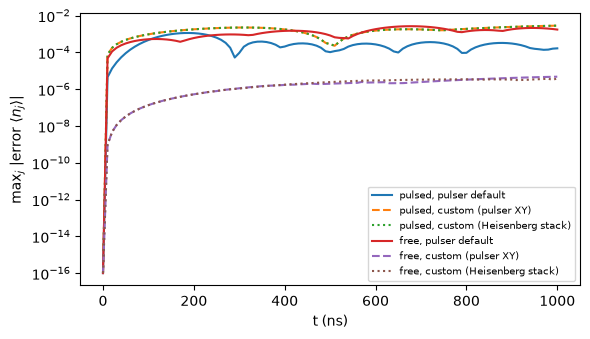

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, case in zip(axes, cases):
    for ax, route in zip(row, routes):
        for j in range(n):
            (line,) = ax.plot(times, exact[case, route]["occ"][:, j], label=f"q{j}")
            ax.plot(times[::5], mps[case, route]["occ"][::5, j], "o", color=line.get_color(), ms=4)
        ax.set_title(f"{case}, {route}"); ax.set_xlabel("t (ns)"); ax.set_ylabel(r"$\langle n_j \rangle$")
    row[0].legend(ncol=2, fontsize=7)
fig.suptitle("exact (lines) vs emu-mps (dots)")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(6, 3.5))
for case in cases:
    for route, ls in zip(routes, ("-", "--", ":")):
        err = (mps[case, route]["occ"] - exact[case, route]["occ"]).abs().max(dim=1).values
        ax.semilogy(times, err + 1e-16, ls, label=f"{case}, {route}")
ax.set_xlabel("t (ns)"); ax.set_ylabel(r"max$_j$ |error $\langle n_j \rangle$|"); ax.legend(fontsize=7)
fig.tight_layout()

The residual error is the TDVP time-splitting error of the long-range couplings (here the ring-closing bond 0-5 and
the dipolar tails): it scales as $dt^2$ and vanishes as `dt` shrinks. The two custom routes are the same Hamiltonian
and agree with each other to round-off.

**TDVP pitfall.** Had the free excitation started on atom 0, i.e. on one end of the strong long-range bond 0-5 of a
product state, the error would be ~1e-2 and would *not* shrink with `dt`: the two-site TDVP projector cannot create the
entanglement a non-adjacent bond needs across the bond-dimension-1 cuts in between (projection error). It is a
property of TDVP, not of the XY model; an excitation away from long-range bonds, a drive (pulsed case) or an already
entangled state avoid it.

## 4. Free hopping

Without drive the XY Hamiltonian conserves the number of excitations: from $|uuduuu\rangle$ the total
$\sum_i\langle n_i\rangle$ stays 1 while the excitation hops along the strong bonds and through the ring-closing bond.
The connected correlator $\langle n_in_j\rangle - \langle n_i\rangle\langle n_j\rangle$ of a single excitation is
$-\langle n_i\rangle\langle n_j\rangle$ off the diagonal (it is never on two atoms at once).

free hopping: max |sum_i <n_i> - 1| = 4.5e-14
connected correlator at 500 ns: max |emu-mps - exact| = 1.8e-06


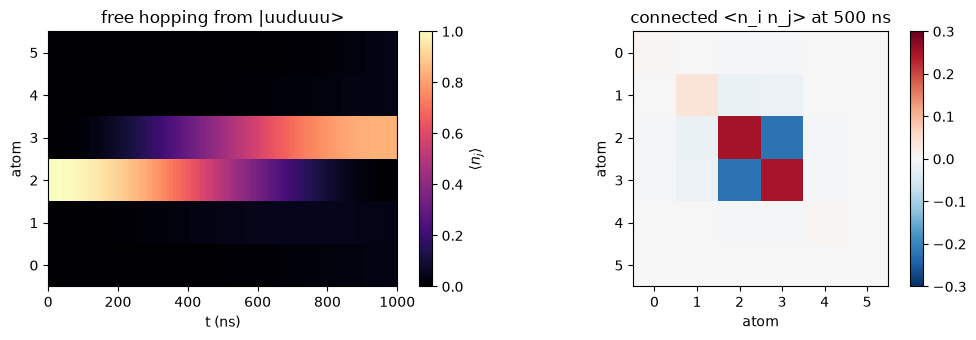

In [6]:
m, e = mps["free", "custom (pulser XY)"], exact["free", "custom (pulser XY)"]
print(f"free hopping: max |sum_i <n_i> - 1| = {(m['occ'].sum(1) - 1).abs().max():.1e}")


def connected(occ, corr):
    return corr - occ[:, None] * occ[None, :]


k = len(times) // 2
C, C_exact = connected(m["occ"][k], m["corr"][k]), connected(e["occ"][k], e["corr"][k])
print(f"connected correlator at {times[k]:.0f} ns: max |emu-mps - exact| = {(C - C_exact).abs().max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
im = axes[0].imshow(m["occ"].T, aspect="auto", origin="lower", extent=(0, T, -0.5, n - 0.5), cmap="magma", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[0], label=r"$\langle n_j \rangle$")
axes[0].set_title("free hopping from |uuduuu>"); axes[0].set_xlabel("t (ns)"); axes[0].set_ylabel("atom")
fig.colorbar(axes[1].imshow(C, cmap="RdBu_r", vmin=-0.3, vmax=0.3), ax=axes[1])
axes[1].set_title(f"connected <n_i n_j> at {times[k]:.0f} ns"); axes[1].set_xlabel("atom"); axes[1].set_ylabel("atom")
fig.tight_layout()

## 5. Small noise from a pulser `NoiseModel`

The noise model goes through pulser like for any simulation and arrives as single-qubit Lindblad operators.
emu-mps runs the Monte Carlo wave-function method: one call = one trajectory, so we average over trajectories and
compare with the exact Lindblad solution (custom XY couplings).

In [7]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
n_traj = 50

noisy = {}
for case, (seq, ud) in cases.items():
    (sd,) = PulserData(sequence=seq, config=MPSConfig(dt=dt, noise_model=noise_model), dt=dt).get_sequences()
    traj = torch.stack([
        torch.stack([torch.as_tensor(o) for o in run_mps("custom (pulser XY)", seq, ud,
                                                          Occupation(evaluation_times=eval_times),
                                                          noise_model=noise_model).occupation])
        for _ in range(n_traj)
    ])
    target = exact_lindblad_dynamics(sd, interaction(J), ud)
    noisy[case] = dict(mc=traj.mean(0), err=traj.std(0) / n_traj**0.5, target=target)
    print(
        f"{case:>6}: {len(sd.lindblad_ops)} Lindblad ops, max |MC - Lindblad| {(traj.mean(0) - target).abs().max():.3f} "
        f"(MC std. error up to {noisy[case]['err'].max():.3f}), "
        f"max |noisy - noiseless| {(target - exact[case, 'custom (pulser XY)']['occ']).abs().max():.3f}"
    )

pulsed: 4 Lindblad ops, max |MC - Lindblad| 0.038 (MC std. error up to 0.032), max |noisy - noiseless| 0.120


  free: 4 Lindblad ops, max |MC - Lindblad| 0.043 (MC std. error up to 0.043), max |noisy - noiseless| 0.138


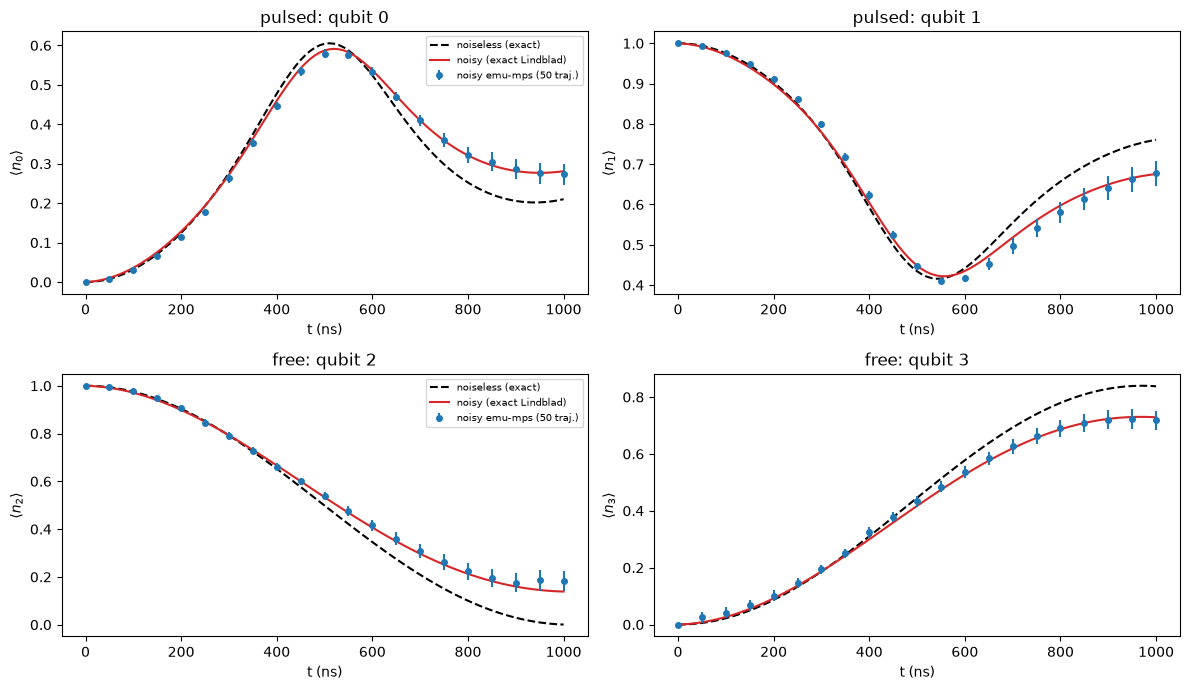

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, case in zip(axes, cases):
    r = noisy[case]
    for ax, j in zip(row, (0, 1) if case == "pulsed" else (2, 3)):  # free: where the excitation starts and hops to
        ax.plot(times, exact[case, "custom (pulser XY)"]["occ"][:, j], "k--", label="noiseless (exact)")
        ax.plot(times, r["target"][:, j], "C3", label="noisy (exact Lindblad)")
        ax.errorbar(times[::5], r["mc"][::5, j], yerr=r["err"][::5, j], fmt="o", color="C0", ms=4,
                    label=f"noisy emu-mps ({n_traj} traj.)")
        ax.set_title(f"{case}: qubit {j}"); ax.set_xlabel("t (ns)"); ax.set_ylabel(rf"$\langle n_{j} \rangle$")
    row[0].legend(fontsize=7)
fig.tight_layout()

**Summary.** The XY model needs nothing beyond pulser's own interface: on the XY channel emu-mps uses the register's
couplings by default, a custom `interaction_matrix` stack `[J, C6]` gives any coupling graph (`[J, 0]` the pure XY
model), and the Heisenberg stack `[J/2, J/2, Jzz]` gives the same model or XXZ variants. emu-mps agrees with the exact
evolution up to the TDVP $dt^2$ error of long-range bonds, and with the exact Lindblad equation within statistical
error under noise.